### Install Dependencies

Pada tahap ini, kita memasang library yang dibutuhkan untuk melakukan pemrosesan teks. Library `textsearch` dan `contractions` digunakan untuk mendukung proses pengolahan teks, sedangkan NLTK (*Natural Language Toolkit*) digunakan untuk memproses bahasa alami.

NLTK juga mengunduh tiga resource, yaitu `punkt`, `punkt_tab`, dan `stopwords`. Resource tersebut diperlukan untuk memisahkan kalimat menjadi token atau kata serta menyediakan daftar kata umum bahasa Inggris yang dapat dihilangkan saat proses preprocessing.

Tahap ini merupakan persiapan sebelum melakukan clustering terhadap deskripsi film.


In [1]:
!pip install textsearch
!pip install contractions
!pip install textsearch

import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     SSRF attempt to restricted IP
[nltk_data]     fd00:aa:bb:2010::b9c7:6c85
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: SSRF attempt to restricted IP
[nltk_data]     fd00:aa:bb:2010::b9c7:6c85
[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: SSRF attempt to restricted IP
[nltk_data]     fd00:aa:bb:2010::b9c7:6c85


False

### Load and View Dataset

Pada tahap ini, dataset film TMDB 5000 dimuat menggunakan library Pandas. Dataset disimpan dalam file `tmdb_5000_movies.csv.gz`, yaitu file CSV yang dikompresi menggunakan format GZIP.

Fungsi `pd.read_csv()` digunakan untuk membaca dataset dan menyimpannya ke dalam variabel `df` dalam bentuk DataFrame. Parameter `compression='gzip'` menunjukkan bahwa file yang dibaca menggunakan kompresi GZIP.

Selanjutnya, fungsi `df.info()` digunakan untuk menampilkan informasi dataset, meliputi jumlah baris, jumlah kolom, nama kolom, jumlah data yang tidak kosong (*non-null*), tipe data, dan penggunaan memori.

Tahap ini bertujuan untuk memahami struktur awal dataset sebelum melakukan pemrosesan teks dan clustering deskripsi film.

In [2]:
import pandas as pd

df = pd.read_csv('tmdb_5000_movies.csv.gz', compression='gzip')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

### View Dataset

Pada tahap ini, fungsi `df.head()` digunakan untuk menampilkan lima baris pertama dari dataset film TMDB 5000. Tampilan ini membantu kita memahami struktur data, melihat nama kolom, dan memeriksa contoh nilai pada setiap kolom sebelum melakukan preprocessing.

Dataset berisi informasi film, seperti judul film (`title`), deskripsi (`overview`), tagline (`tagline`), popularitas (`popularity`), dan informasi lainnya. Data tersebut akan digunakan pada tahap berikutnya untuk mengelompokkan film berdasarkan kemiripan teks deskripsinya.

In [3]:
df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


### Data Preprocessing

Pada tahap ini, kita melakukan persiapan data sebelum proses text clustering. Pertama, dataset dimuat kembali menggunakan Pandas, kemudian dipilih empat kolom yang diperlukan, yaitu `title`, `tagline`, `overview`, dan `popularity`.

Selanjutnya, nilai kosong pada kolom `tagline` diganti dengan string kosong. Kolom `tagline` dan `overview` kemudian digabungkan menjadi kolom baru bernama `description`. Kolom ini akan menjadi sumber teks utama untuk proses clustering film.

Fungsi `dropna()` digunakan untuk menghapus baris yang masih memiliki nilai kosong, sedangkan `reset_index()` digunakan untuk mengatur ulang indeks data. Tahap ini bertujuan menyiapkan dataset agar dapat digunakan dalam proses normalisasi teks pada tahap selanjutnya.

In [4]:

df = pd.read_csv('tmdb_5000_movies.csv.gz', compression='gzip')
df = df[['title', 'tagline', 'overview', 'popularity']].copy()
df['tagline'] = df['tagline'].fillna('')
df['description'] = df['tagline'] + ' ' + df['overview']
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
df.info()
print("Jumlah data:", len(df))


<class 'pandas.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        4800 non-null   str    
 1   tagline      4800 non-null   str    
 2   overview     4800 non-null   str    
 3   popularity   4800 non-null   float64
 4   description  4800 non-null   str    
dtypes: float64(1), str(4)
memory usage: 187.6 KB
Jumlah data: 4800


### View Processed Dataset

Pada tahap ini, fungsi `df.head()` digunakan untuk menampilkan lima baris pertama dari dataset setelah proses preprocessing.

Dataset sekarang memiliki kolom `description`, yaitu gabungan dari `tagline` dan `overview`. Kolom ini akan digunakan sebagai data teks utama dalam proses text clustering. Dengan menampilkan data, kita dapat memeriksa apakah kolom baru telah terbentuk dengan benar dan apakah informasi film masih tersimpan sesuai kebutuhan.

Tahap ini merupakan pemeriksaan awal sebelum teks dinormalisasi pada proses berikutnya.

In [5]:
df.head()

,title,tagline,overview,popularity,description
0,Avatar,Enter the World of Pandora.,"In the 22nd century, a paraplegic Marine is di...",150.437577,Enter the World of Pandora. In the 22nd centur...
1,Pirates of the Caribbean: At World's End,"At the end of the world, the adventure begins.","Captain Barbossa, long believed to be dead, ha...",139.082615,"At the end of the world, the adventure begins...."
2,Spectre,A Plan No One Escapes,A cryptic message from Bond’s past sends him o...,107.376788,A Plan No One Escapes A cryptic message from B...
3,The Dark Knight Rises,The Legend Ends,Following the death of District Attorney Harve...,112.312950,The Legend Ends Following the death of Distric...
4,John Carter,"Lost in our world, found in another.","John Carter is a war-weary, former military ca...",43.926995,"Lost in our world, found in another. John Cart..."


### Text Normalization

Pada tahap ini, dilakukan normalisasi teks terhadap deskripsi film yang telah disiapkan sebelumnya. Proses ini bertujuan membersihkan teks agar lebih konsisten dan mudah diolah dalam proses text clustering.

Normalisasi dilakukan dengan menghapus karakter khusus, mengubah seluruh teks menjadi huruf kecil, menghapus spasi di awal dan akhir teks, serta memperbaiki singkatan menggunakan library `contractions`. Selanjutnya, teks dipecah menjadi token menggunakan `nltk.word_tokenize()`.

Kata-kata umum bahasa Inggris yang terdapat dalam daftar stopwords dihapus agar kata yang kurang informatif tidak terlalu memengaruhi proses clustering. Fungsi `normalize_document()` digunakan untuk memproses setiap deskripsi film, kemudian hasilnya disimpan dalam variabel `norm_corpus`.

Hasil normalisasi ini akan digunakan pada tahap berikutnya untuk mengubah teks menjadi representasi numerik menggunakan metode ekstraksi fitur.

In [6]:
import nltk
import re
import numpy as np
import contractions

stop_words = nltk.corpus.stopwords.words('english')

def normalize_document(doc):
    doc = re.sub(r'[^a-zA-Z0-9\s]', '', str(doc), flags=re.I | re.A)
    doc = doc.lower()
    doc = doc.strip()
    doc = contractions.fix(doc)
    tokens = nltk.word_tokenize(doc)
    filtered_tokens = [token for token in tokens if token not in stop_words]
    doc = ' '.join(filtered_tokens)
    return doc

normalize_corpus = np.vectorize(normalize_document)
norm_corpus = normalize_corpus(list(df['description']))
len(norm_corpus)

4800

### Feature Extraction

Pada tahap ini, kita mengubah teks deskripsi film yang telah dinormalisasi menjadi representasi numerik menggunakan `CountVectorizer` dari library Scikit-learn.

Komputer tidak dapat langsung memahami teks seperti manusia. Oleh karena itu, teks perlu diubah menjadi kumpulan fitur berupa kata dan kombinasi kata yang dapat diolah oleh algoritma clustering.

Parameter `ngram_range=(1, 2)` digunakan untuk mengambil unigram (satu kata) dan bigram (kombinasi dua kata). Parameter `min_df=0.001` mengabaikan fitur yang muncul pada kurang dari 0,1% dokumen, sedangkan `max_df=0.99` mengabaikan fitur yang muncul pada lebih dari 99% dokumen.

Parameter `stop_words` digunakan untuk menghilangkan kata-kata umum bahasa Inggris serta beberapa kata tambahan yang dianggap kurang informatif. Hasil ekstraksi fitur disimpan dalam variabel `cv_matrix` dalam bentuk matriks sparse.

Matriks ini akan digunakan sebagai masukan bagi algoritma K-Means untuk mengelompokkan film berdasarkan kemiripan teksnya.

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(
    ngram_range=(1, 2),
    min_df=0.001,
    max_df=0.99,
    stop_words=stop_words + ['one', 'two', 'three', 'four', 'five', 'get']
)

cv_matrix = cv.fit_transform(norm_corpus)

print("Ukuran matriks fitur:", cv_matrix.shape)

Ukuran matriks fitur: (4800, 6100)


### K-Means Clustering

Pada tahap ini, algoritma K-Means digunakan untuk mengelompokkan film berdasarkan kemiripan teks deskripsinya. Sebelum proses clustering dilakukan, teks film telah diubah menjadi representasi numerik menggunakan `CountVectorizer`.

Parameter `n_clusters=6` digunakan untuk menentukan jumlah cluster yang akan dibentuk, yaitu enam kelompok film. Parameter `max_iter=10000` menentukan jumlah maksimum iterasi dalam proses clustering, sedangkan `n_init=100` menentukan jumlah percobaan dengan inisialisasi centroid yang berbeda. Parameter `random_state=42` digunakan agar hasil proses dapat direproduksi dengan pengaturan yang sama.

Selanjutnya, fungsi `fit()` digunakan untuk melatih model K-Means menggunakan matriks fitur `cv_matrix`. Hasil pengelompokan disimpan dalam variabel `km`, dan label cluster setiap film dapat diakses melalui atribut `km.labels_`.

Tahap ini bertujuan membentuk kelompok film berdasarkan kemiripan fitur teks sehingga hasilnya dapat dianalisis pada tahap berikutnya.

In [8]:
from sklearn.cluster import KMeans

km = KMeans(
    n_clusters=6,
    max_iter=10000,
    n_init=100,
    random_state=42
)

km.fit(cv_matrix)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",6
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",100
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",10000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](6, 6100)",

### Counting Movies in Each Cluster

Pada tahap ini, library `Counter` dari modul `collections` digunakan untuk menghitung jumlah film yang masuk ke setiap cluster hasil algoritma K-Means. Label cluster diperoleh dari atribut `km.labels_`.

Hasil perhitungan membantu kita memahami distribusi film pada enam cluster yang telah dibentuk. Setiap film masuk ke salah satu cluster berdasarkan kemiripan fitur teksnya. Jumlah film pada setiap cluster dapat berbeda karena algoritma mengelompokkan data berdasarkan karakteristik yang ditemukan.

In [9]:
from collections import Counter

Counter(km.labels_)

Counter({np.int32(0): 2677,
         np.int32(3): 656,
         np.int32(4): 525,
         np.int32(5): 473,
         np.int32(1): 468,
         np.int32(2): 1})

### Assigning Cluster Labels

Pada tahap ini, label cluster hasil algoritma K-Means disimpan ke dalam kolom baru bernama `kmeans_cluster` pada DataFrame `df`. Label tersebut menunjukkan kelompok tempat setiap film berada.

Dengan menyimpan label cluster bersama informasi film, kita dapat menggabungkan hasil clustering dengan judul dan popularitas film. Data ini akan digunakan untuk menampilkan film populer pada setiap cluster di tahap berikutnya.

In [10]:
df['kmeans_cluster'] = km.labels_

### Preparing Movie Clusters

Pada tahap ini, kita menyiapkan data untuk melihat film populer dalam setiap cluster. Kolom yang dipilih adalah `title`, `kmeans_cluster`, dan `popularity`.

Data diurutkan berdasarkan label cluster dan popularitas film secara menurun. Selanjutnya, fungsi `groupby()` dan `head(20)` digunakan untuk mengambil maksimal 20 film teratas dari setiap cluster. Hasilnya disimpan dalam variabel `movie_clusters` agar lebih mudah dianalisis.

In [11]:
movie_clusters = (
    df[['title', 'kmeans_cluster', 'popularity']]
    .sort_values(
        by=['kmeans_cluster', 'popularity'],
        ascending=False
    )
    .groupby('kmeans_cluster')
    .head(20)
)

movie_clusters = movie_clusters.copy(deep=True)

### Analyzing Movie Clusters

Pada tahap ini, kita menganalisis karakteristik setiap cluster berdasarkan kata-kata yang paling berpengaruh dan film-film populer di dalamnya. Fungsi `get_feature_names_out()` digunakan untuk memperoleh nama fitur yang dibuat oleh `CountVectorizer`.

Selanjutnya, `cluster_centers_` digunakan untuk memperoleh nilai pusat cluster. Fitur diurutkan berdasarkan nilainya dari yang terbesar, kemudian diambil 30 fitur teratas untuk setiap cluster. Daftar fitur tersebut ditampilkan bersama judul film populer agar kita dapat memahami karakteristik teks yang membedakan satu cluster dengan cluster lainnya.

In [12]:
NUM_CLUSTERS = 6
feature_names = cv.get_feature_names_out()
topn_features = 30
ordered_centroids = km.cluster_centers_.argsort()[:, ::-1]

for cluster_num in range(NUM_CLUSTERS):
    key_features = [
        feature_names[index]
        for index in ordered_centroids[cluster_num, :topn_features]
    ]

    movies = movie_clusters[
        movie_clusters['kmeans_cluster'] == cluster_num
    ]['title'].values.tolist()

    print('CLUSTER #' + str(cluster_num + 1))
    print('Key Features:', key_features)
    print('Popular Movies:', movies)
    print('-' * 80)

CLUSTER #1
Key Features: ['young', 'story', 'love', 'family', 'find', 'must', 'time', 'back', 'friends', 'years', 'way', 'film', 'home', 'help', 'lives', 'town', 'father', 'take', 'finds', 'hes', 'school', 'first', 'woman', 'never', 'group', 'together', 'team', 'go', 'make', 'takes']
Popular Movies: ['Interstellar', 'Guardians of the Galaxy', 'Pirates of the Caribbean: The Curse of the Black Pearl', 'Dawn of the Planet of the Apes', 'The Hunger Games: Mockingjay - Part 1', 'Big Hero 6', 'Whiplash', 'The Dark Knight', 'The Martian', "Pirates of the Caribbean: Dead Man's Chest", 'X-Men: Apocalypse', 'Rise of the Planet of the Apes', 'The Lord of the Rings: The Fellowship of the Ring', 'Pirates of the Caribbean: On Stranger Tides', "One Flew Over the Cuckoo's Nest", 'The Hunger Games: Mockingjay - Part 2', 'Star Wars', 'Brave', 'The Lord of the Rings: The Return of the King', 'The Hobbit: The Battle of the Five Armies']
---------------------------------------------------------------------

## Bagian 2 — Clustering menggunakan FastText Embeddings
Pada bagian ini, kita beralih dari fitur berdasarkan frekuensi kata ke word embeddings. Metode ini mempelajari representasi kata dalam bentuk vektor numerik, kemudian menggunakannya untuk membentuk representasi setiap deskripsi film.

### Installing Gensim

Pada tahap ini, kita memastikan library Gensim tersedia untuk melakukan pemodelan word embeddings menggunakan FastText. Gensim menyediakan berbagai metode untuk mempelajari representasi kata dalam bentuk vektor numerik.

Library ini digunakan pada tahap berikutnya untuk mempelajari hubungan antarkata dalam deskripsi film. Karena Gensim sudah berhasil dipasang pada environment `gensim314`, tahap ini dapat digunakan untuk memastikan instalasinya tersedia di kernel notebook.

In [13]:
import gensim

print(gensim.__version__)


4.4.0


### FastText Word Embeddings

Pada tahap ini, model FastText digunakan untuk mempelajari representasi kata berdasarkan kumpulan deskripsi film. Sebelum pelatihan, setiap deskripsi dipecah menjadi daftar kata menggunakan `split()` setelah melalui fungsi normalisasi.

Parameter `vector_size=300` menentukan ukuran vektor setiap kata, sedangkan `window=40` menentukan rentang konteks kata yang dipertimbangkan. Parameter `min_count=3` mengatur jumlah minimum kemunculan kata, `workers=4` menentukan jumlah pekerja komputasi, `sg=1` memilih arsitektur Skip-gram, dan `epochs=100` menentukan jumlah putaran pelatihan.

Hasilnya disimpan dalam variabel `ft_model`. Model ini akan digunakan untuk membentuk representasi numerik dari seluruh deskripsi film.

In [14]:
from gensim.models import FastText

tokenized_docs = [
    normalize_document(doc).split()
    for doc in df['description']
]

tokenized_docs = [doc for doc in tokenized_docs if doc]

print("Jumlah dokumen:", len(tokenized_docs))

ft_model = FastText(
    sentences=tokenized_docs,
    vector_size=100,
    window=5,
    min_count=3,
    workers=1,
    sg=1,
    epochs=5,
    seed=42
)

print("FastText berhasil dilatih")
print("Ukuran vektor:", ft_model.vector_size)
print("Jumlah kata:", len(ft_model.wv))
print("Jumlah dokumen:", len(tokenized_docs))

Jumlah dokumen: 4799
FastText berhasil dilatih
Ukuran vektor: 100
Jumlah kata: 8697
Jumlah dokumen: 4799


### Document Vectorization

Pada tahap ini, setiap deskripsi film diubah menjadi sebuah vektor numerik berdasarkan representasi kata yang telah dipelajari oleh model FastText. Vektor dokumen diperoleh dengan menghitung rata-rata vektor dari kata-kata yang terdapat dalam deskripsi tersebut.

Hasilnya adalah matriks numerik yang mewakili seluruh dokumen film. Matriks ini digunakan sebagai masukan untuk algoritma K-Means agar film dapat dikelompokkan berdasarkan kemiripan teksnya.

Deskripsi yang kosong atau tidak memiliki kata dalam vocabulary akan diwakili oleh vektor nol, sehingga jumlah vektor tetap sesuai dengan jumlah baris dataset.

In [15]:
import numpy as np

def averaged_word2vec_vectorizer(corpus, model, num_features):
    features = np.zeros((len(corpus), num_features), dtype=np.float32)

    for i, tokens in enumerate(corpus):
        valid_vectors = [
            model.wv[token]
            for token in tokens
            if token in model.wv
        ]

        if valid_vectors:
            features[i] = np.mean(valid_vectors, axis=0)

    return features

tokenized_all_docs = [
    normalize_document(doc).split()
    for doc in df['description']
]

doc_vecs_ft = averaged_word2vec_vectorizer(
    tokenized_all_docs,
    ft_model,
    ft_model.vector_size
)

print("Ukuran matriks vektor:", doc_vecs_ft.shape)
print("Jumlah dokumen:", doc_vecs_ft.shape[0])
print("Ukuran vektor:", doc_vecs_ft.shape[1])

Ukuran matriks vektor: (4800, 100)
Jumlah dokumen: 4800
Ukuran vektor: 100


### Document Vectorization

Pada tahap ini, setiap dokumen film diubah menjadi vektor numerik menggunakan model FastText yang telah dilatih. Fungsi `averaged_word2vec_vectorizer()` menghitung rata-rata vektor kata dalam setiap dokumen sehingga satu film direpresentasikan oleh satu vektor.

Vektor dokumen digunakan sebagai masukan untuk algoritma K-Means pada tahap selanjutnya. Pada modul, ukuran matriks yang diharapkan adalah `(4800, 300)`. Karena model FastText yang berhasil dilatih menggunakan `vector_size=100`, ukuran matriks pada pengerjaan ini akan menjadi `(4800, 100)`.

In [16]:
doc_vecs_ft = averaged_word2vec_vectorizer(
    tokenized_all_docs,
    ft_model,
    ft_model.vector_size
)

print("Ukuran matriks:", doc_vecs_ft.shape)

Ukuran matriks: (4800, 100)


### FastText-Based Clustering

Pada tahap ini, algoritma K-Means digunakan untuk mengelompokkan film berdasarkan kemiripan vektor dokumennya. Parameter `n_clusters=6` menentukan bahwa film akan dibagi menjadi enam kelompok.

Parameter `max_iter=10000` menentukan batas maksimum iterasi, `n_init=100` menentukan jumlah percobaan awal pengelompokan, dan `random_state=42` digunakan agar hasil dapat direproduksi. Hasil clustering disimpan pada variabel `km`.

In [17]:
from sklearn.cluster import KMeans

NUM_CLUSTERS = 6

km = KMeans(
    n_clusters=NUM_CLUSTERS,
    max_iter=10000,
    n_init=100,
    random_state=42
)

km.fit(doc_vecs_ft)

print("Clustering FastText selesai.")
print("Jumlah cluster:", NUM_CLUSTERS)

Clustering FastText selesai.
Jumlah cluster: 6


### Cluster Distribution

Tahap ini menghitung jumlah film yang masuk ke setiap cluster menggunakan `Counter`. Label cluster berasal dari hasil prediksi K-Means yang tersimpan dalam `km.labels_`.

Distribusi tersebut membantu melihat apakah film tersebar merata atau justru sebagian besar terkumpul dalam satu cluster. Jumlah seluruh film pada distribusi seharusnya sama dengan jumlah dokumen yang diproses.

In [18]:
from collections import Counter

cluster_counts = Counter(km.labels_)

print("Distribusi cluster:", cluster_counts)
print("Total film:", sum(cluster_counts.values()))

Distribusi cluster: Counter({np.int32(1): 1361, np.int32(0): 1160, np.int32(2): 755, np.int32(3): 717, np.int32(4): 416, np.int32(5): 391})
Total film: 4800


### Organizing Cluster Results

Pada tahap ini, label cluster dari K-Means disimpan ke kolom `kmeans_cluster` dalam DataFrame `df`. Selanjutnya, data film diurutkan berdasarkan cluster dan popularitas dari nilai tertinggi ke terendah.

Fungsi `groupby()` digunakan untuk mengelompokkan film berdasarkan label cluster, sedangkan `head(30)` mengambil maksimal 30 film teratas dari setiap cluster. Hasilnya disimpan dalam `movie_clusters` agar mudah dianalisis pada tahap berikutnya.

In [19]:
df['kmeans_cluster'] = km.labels_

movie_clusters = (
    df[['title', 'kmeans_cluster', 'popularity']]
    .sort_values(
        by=['kmeans_cluster', 'popularity'],
        ascending=[True, False]
    )
    .groupby('kmeans_cluster')
    .head(30)
    .copy()
)

movie_clusters.head()

,title,kmeans_cluster,popularity
1,Pirates of the Caribbean: At World's End,0,139.082615
262,The Lord of the Rings: The Fellowship of the Ring,0,138.049577
2294,Spirited Away,0,118.968562
197,Harry Potter and the Philosopher's Stone,0,109.984351
423,Bruce Almighty,0,109.684788


### Popular Movies in Each Cluster

Tahap ini menampilkan daftar film populer yang termasuk dalam masing-masing cluster. Perulangan `for` digunakan untuk memproses enam cluster secara berurutan.

Dengan melihat judul film dalam setiap kelompok, kita dapat mengamati apakah terdapat kesamaan tema atau karakteristik di antara film-film yang dikelompokkan oleh FastText. Namun, kesamaan tema perlu ditafsirkan dari hasil film yang muncul dan tidak hanya dari nomor cluster.

In [20]:
for cluster_num in range(NUM_CLUSTERS):
    movies = movie_clusters.loc[
        movie_clusters['kmeans_cluster'] == cluster_num,
        'title'
    ].tolist()

    print(f"CLUSTER #{cluster_num + 1}")
    print("Popular Movies:", movies)
    print("-" * 80)

CLUSTER #1
Popular Movies: ["Pirates of the Caribbean: At World's End", 'The Lord of the Rings: The Fellowship of the Ring', 'Spirited Away', "Harry Potter and the Philosopher's Stone", 'Bruce Almighty', 'Monsters, Inc.', 'Furious 7', 'Cinderella', 'It Follows', 'The Twilight Saga: Breaking Dawn - Part 2', 'Ice Age', 'Black Swan', "Pan's Labyrinth", 'The Amazing Spider-Man', 'Birdman', 'The Amazing Spider-Man 2', 'Monsters University', 'Prisoners', 'The Purge: Anarchy', 'The Hangover', 'Night at the Museum: Battle of the Smithsonian', 'Taken', 'American Beauty', 'The Pursuit of Happyness', 'The Equalizer', 'Kill Bill: Vol. 1', 'Harry Potter and the Prisoner of Azkaban', 'Edge of Tomorrow', 'The Incredibles', 'Back to the Future']
--------------------------------------------------------------------------------
CLUSTER #2
Popular Movies: ['Interstellar', 'Deadpool', 'Pirates of the Caribbean: The Curse of the Black Pearl', 'Dawn of the Planet of the Apes', 'Terminator Genisys', 'Captain 

### Hierarchical Clustering

Pada tahap ini, kita mengimpor library yang diperlukan untuk melakukan hierarchical clustering dan menampilkan hasilnya dalam bentuk dendrogram.

Hierarchical clustering adalah metode pengelompokan data secara bertahap. Metode *agglomerative* dimulai dengan menganggap setiap data sebagai kelompok tersendiri, kemudian menggabungkan kelompok yang memiliki kedekatan tertentu. Pada modul ini, metode Ward digunakan sebagai kriteria penggabungan cluster.

In [21]:
from scipy.cluster.hierarchy import ward, dendrogram
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import numpy as np

### Calculate Linkage Matrix Using Cosine Similarity

Tahap ini membuat fungsi `ward_hierarchical_clustering()` untuk menghitung kemiripan antarvektor dokumen menggunakan cosine similarity. Nilai kemiripan kemudian diubah menjadi cosine distance dengan rumus `1 - cosine_similarity`.

Fungsi `ward()` digunakan untuk membentuk linkage matrix, yaitu informasi mengenai proses penggabungan cluster. Linkage matrix nantinya menjadi masukan untuk membuat dendrogram.

In [22]:
def ward_hierarchical_clustering(feature_matrix):
    cosine_distance = 1 - cosine_similarity(feature_matrix)
    linkage_matrix = ward(cosine_distance)
    return linkage_matrix

### Plot Hierarchical Structure as a Dendrogram

Dendrogram merupakan diagram berbentuk pohon yang menunjukkan bagaimana data atau cluster digabungkan secara bertahap. Cabang yang bergabung pada jarak lebih rendah menunjukkan penggabungan pada tingkat jarak yang lebih kecil.

Pada tahap ini, fungsi `plot_hierarchical_clusters()` digunakan untuk menampilkan struktur hierarchical clustering. Parameter `p` mengatur jumlah kelompok terakhir yang ditampilkan pada dendrogram agar visualisasi lebih mudah dibaca, sedangkan `figure_size` mengatur ukuran gambar.

In [23]:
def plot_hierarchical_clusters(linkage_matrix, movie_data, p=100, figure_size=(8, 12)):
    movie_titles = movie_data['title'].tolist()
    number_of_movies = len(movie_titles)

    fig, ax = plt.subplots(figsize=figure_size)

    def label_function(cluster_id):
        if cluster_id < number_of_movies:
            return movie_titles[int(cluster_id)]
        return f"Cluster {int(cluster_id)}"

    dendrogram(
        linkage_matrix,
        truncate_mode='lastp',
        p=p,
        orientation='left',
        leaf_label_func=label_function,
        leaf_font_size=8,
        ax=ax
    )

    ax.tick_params(axis='x', bottom=False, top=False, labelbottom=False)
    plt.tight_layout()
    plt.savefig('movie_hierarchical_clusters.png', dpi=200)
    plt.show()

### Generate Linkage Matrix

Pada tahap ini, fungsi `ward_hierarchical_clustering()` dijalankan menggunakan representasi numerik dokumen film yang telah dibuat dengan FastText. Hasilnya disimpan dalam variabel `linkage_matrix`.

Jika terdapat \(n\) dokumen, linkage matrix memiliki \(n-1\) baris dan empat kolom. Setiap baris menyimpan dua cluster yang digabungkan, jarak penggabungan, dan jumlah data dalam cluster hasil penggabungan.

In [24]:
linkage_matrix = ward_hierarchical_clustering(doc_vecs_ft)

print("Ukuran linkage matrix:", linkage_matrix.shape)

Ukuran linkage matrix: (4799, 4)


### Inspect Linkage Matrix

Tahap ini menampilkan isi linkage matrix untuk memeriksa hasil penggabungan cluster. Pengaturan `np.set_printoptions(suppress=True)` membuat angka kecil ditampilkan tanpa notasi ilmiah jika memungkinkan.

Empat kolom pada linkage matrix menunjukkan dua indeks cluster yang digabungkan, jarak penggabungannya, serta jumlah dokumen dalam cluster yang terbentuk.

In [25]:
np.set_printoptions(suppress=True)
print(linkage_matrix)

[[1688.         4742.            0.00564566    2.        ]
 [ 514.         2664.            0.00629453    2.        ]
 [1719.         2798.            0.00764191    2.        ]
 ...
 [9590.         9593.            8.74455588  505.        ]
 [9595.         9596.           15.05570137 4799.        ]
 [4399.         9597.           97.49684107 4800.        ]]


### Visualize Hierarchical Clusters

Tahap terakhir menampilkan hasil hierarchical clustering dalam bentuk dendrogram. Parameter `p=200` membatasi visualisasi pada 200 kelompok atau cabang terakhir agar diagram tidak terlalu padat. Ukuran gambar `(18, 30)` digunakan agar struktur dan label lebih mudah diamati.

Gambar juga disimpan sebagai `movie_hierarchical_clusters.png` sehingga dapat digunakan kembali untuk dokumentasi atau laporan praktikum.

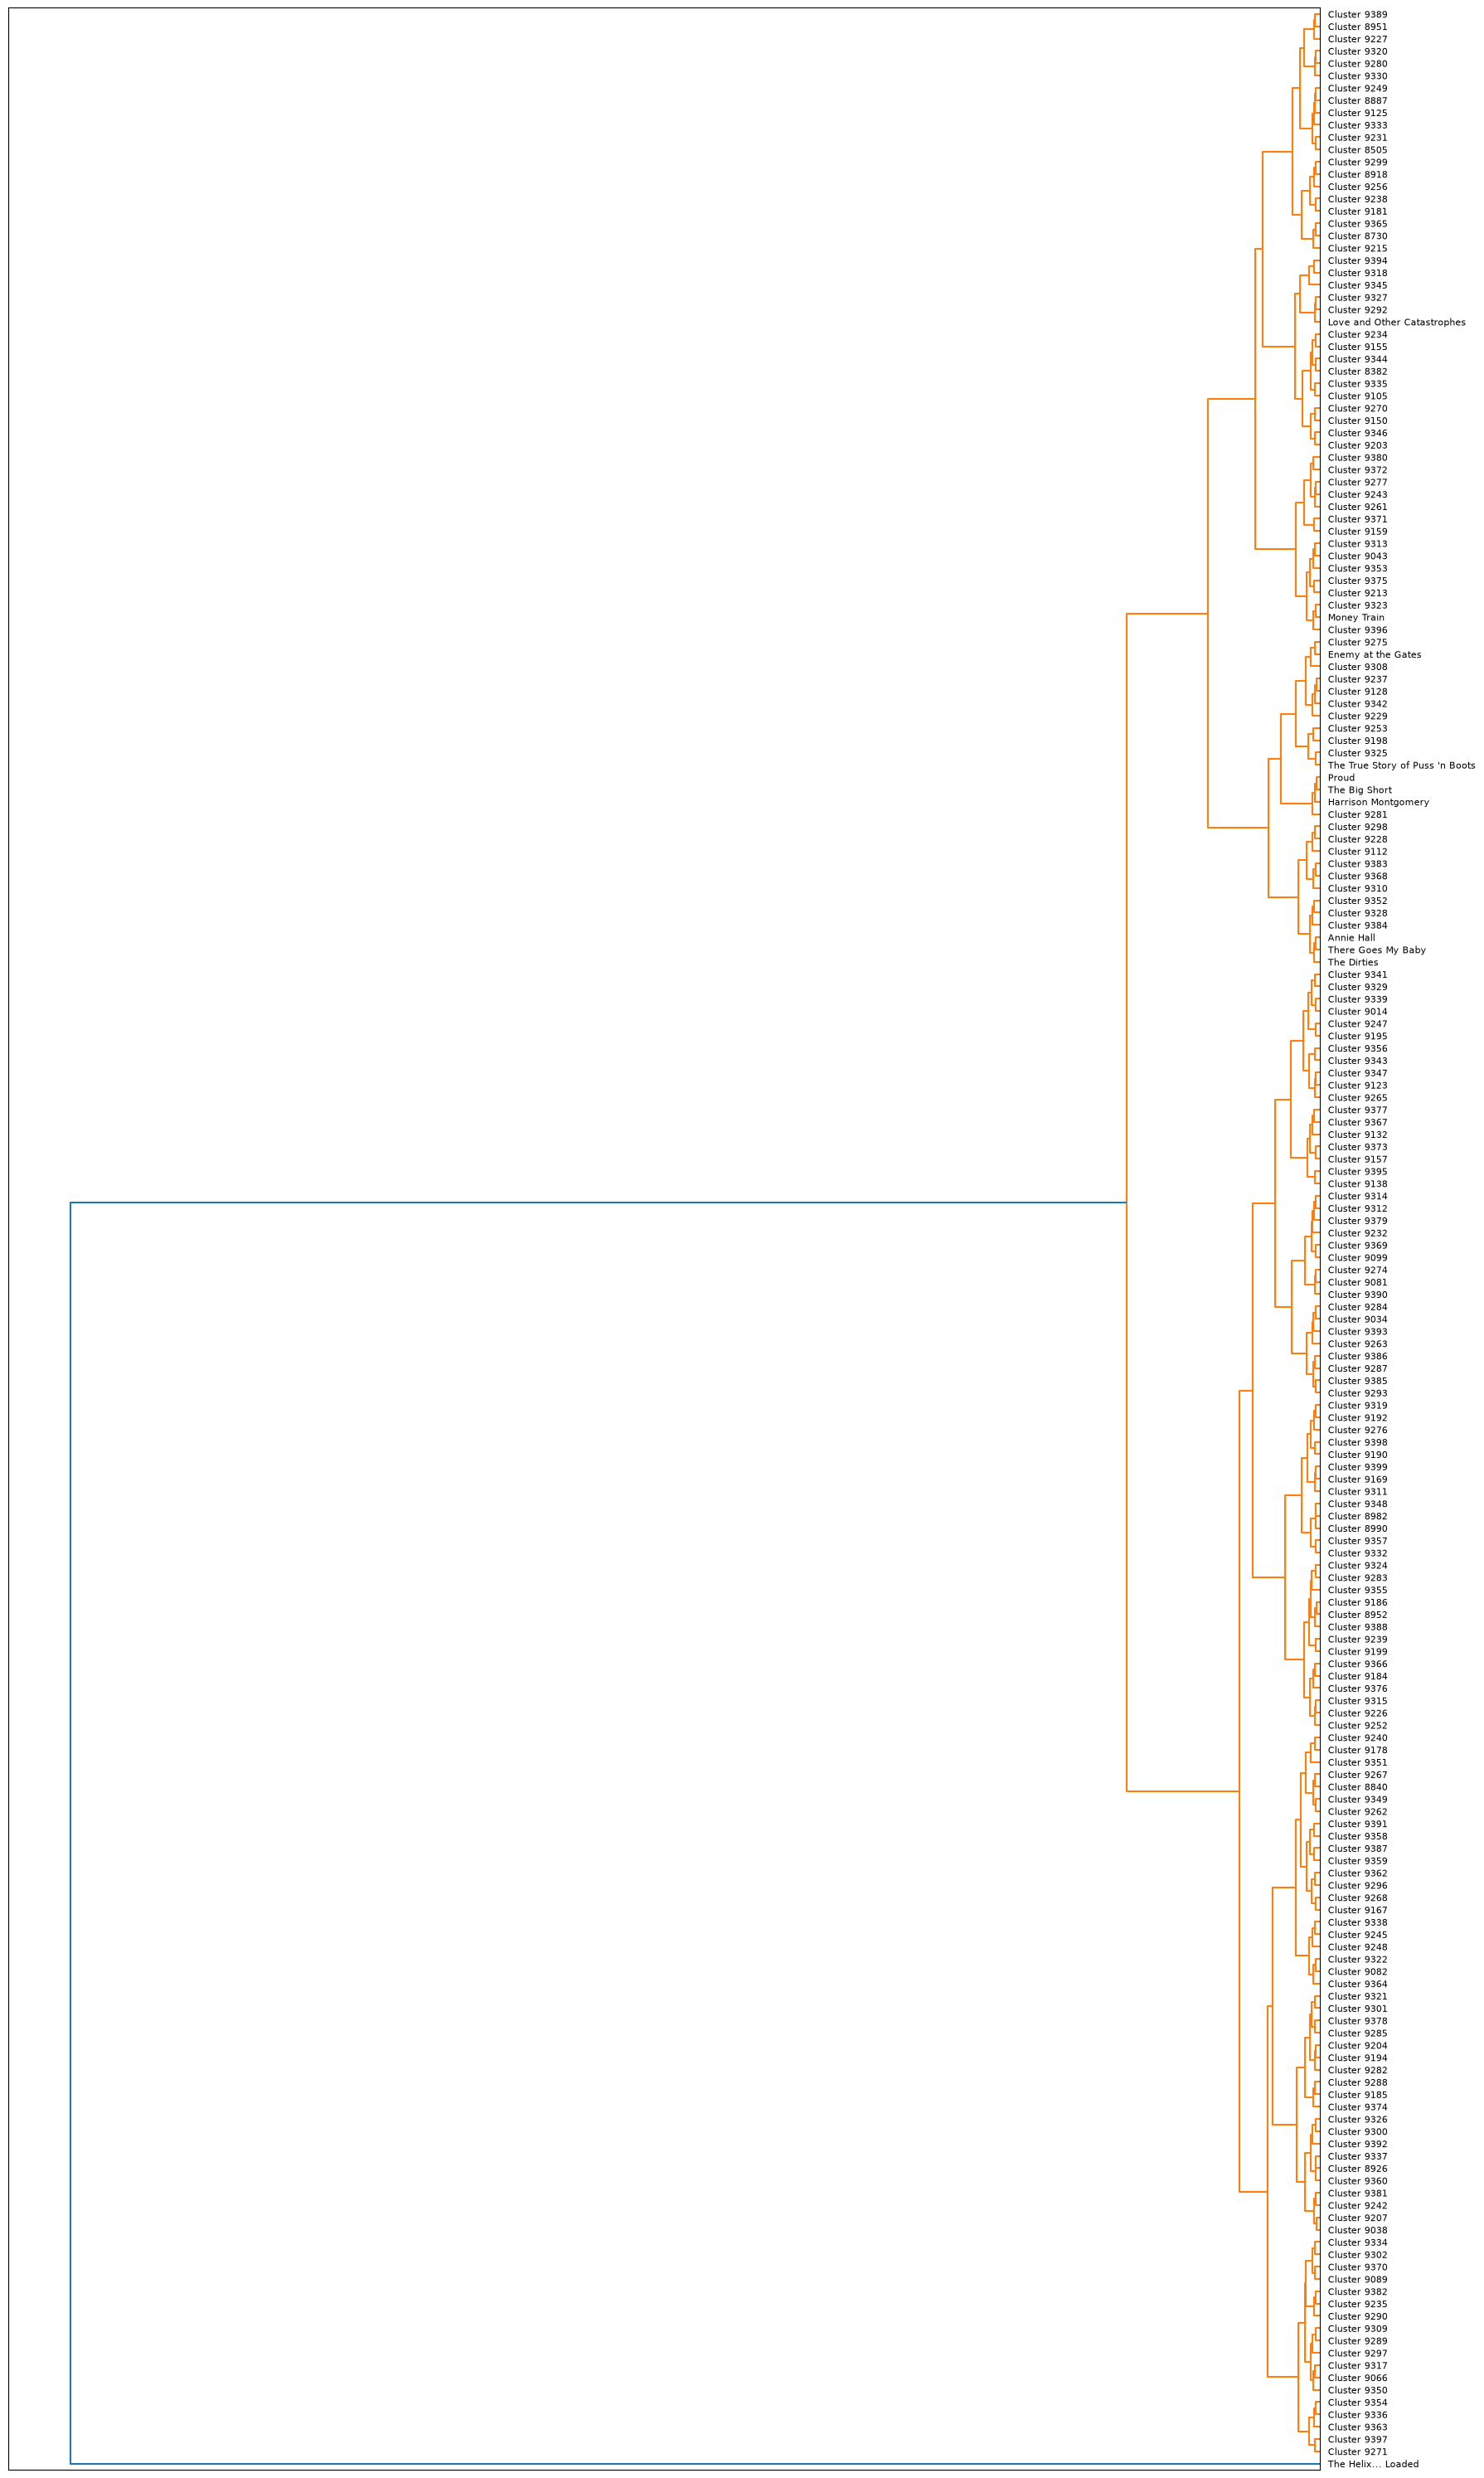

In [26]:
plot_hierarchical_clusters(
    linkage_matrix,
    movie_data=df,
    p=200,
    figure_size=(18, 30)
)